# 抓杯子：先使用已发布的成熟配方

推荐从 [14号：已发布权重与完整结果](14_smolvla_end_to_end.ipynb) 查看 SmolVLA［小型视觉语言动作模型］保护版本：红杯27/30、蓝杯30/30，合计57/60（95%）。课程已保存对应输出、曲线和成功／失败视频；现有数据、权重与配置可以直接复用。

[公开权重与零训练入口](https://huggingface.co/Datawhale/every-embodied-smolvla-mujoco-pnp) · [已开源的配方与57/60结果](https://github.com/datawhalechina/every-embodied/blob/main/16-专题组队学习/04-AMD-ROCm策略复刻专题/README_04_SmolVLA_ROCm迁移与采样加权.md) · [闭环部署说明](11_mujoco_closed_loop_deploy.ipynb)

默认阅读已保存输出，复训开关保持关闭。只有需要主动复现实验时，才执行对应配方的训练或评估阶段。

补充实验：[19号5000步新实验，2/30](19_cup_collect_train_evaluate.ipynb)；[20号20000步新实验，3/30](20_cup_deterministic_train_evaluate.ipynb)。20号复用19号同一批40条数据，采用独立训练配方与权重，保留真实输出、全部评估记录和视频，供比较与诊断。


In [1]:
from pathlib import Path
import json, os, sys
TOPIC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code/amd_benchmarks').is_dir())
sys.path.insert(0, str(TOPIC / 'code'))
from amd_benchmarks.evidence import table
from amd_benchmarks.catalog import show_media, load_record, preview_stage
print('下表为历史红蓝杯配方的完整结果；新红杯实训另见19号笔记本。')


下表为历史红蓝杯配方的完整结果；新红杯实训另见19号笔记本。


## 已归档结果与范围


In [2]:
record = json.loads((TOPIC/'assets/smolvla_protected_summary.json').read_text())
table(['模型','严格物理成功','红杯','蓝杯'],[[record['model'],str(record['physical_success_count'])+'/'+str(record['episodes']),record['by_instruction']['red'],record['by_instruction']['blue']]])


模型,严格物理成功,红杯,蓝杯
SmolVLA,57/60,27/30,30/30


## 本地视频与原始出处

下列完整视频和图片均已随课程包恢复，观看无需联网。素材来自设备原教程目录，内容指纹和完整解码结果保存在 `reproducibility/cup-restored-media.json`。各模型使用各自的原配方；包含视觉／历史辅助头的演示单独标注。


In [3]:
from IPython.display import display, Video, Image, Markdown
media = [
    ("轻量语言策略：红杯成功", "smolvla_weighted500_red_success_seed0.mp4"),
    ("轻量语言策略：蓝杯成功", "smolvla_weighted500_blue_success_seed0.mp4"),
    ("轻量语言策略：红杯失败", "smolvla_weighted500_red_failure_seed8.mp4"),
    ("四视角成功：使用视觉与历史辅助头", "pnp_four_view_strict_success.mp4"),
    ("原始策略与末端收尾器诊断对照", "pi0_ep2_raw_vs_finisher_side_by_side.mp4"),
    ("末端增量动作策略", "pi05_eefdelta_h5_seed2133.mp4"),
    ("规范动作接口策略", "pi05_canonical_s800_seed1003.mp4"),
]
for label, filename in media:
    assert (TOPIC / "assets" / filename).is_file(), filename
    original = TOPIC / "assets" / filename
    compatible = original.with_name(original.stem + ".browser.mp4")
    video_path = compatible if compatible.is_file() else original
    display(Markdown(label))
    display(Video(str(video_path), embed=True, width=640))


轻量语言策略：红杯成功

轻量语言策略：蓝杯成功

轻量语言策略：红杯失败

四视角成功：使用视觉与历史辅助头

原始策略与末端收尾器诊断对照

末端增量动作策略

规范动作接口策略

## 已保存的曲线和动作过程

下方红蓝成功率曲线为历史每颜色10回合的采样诊断；上方57/60表格对应另一次每颜色30回合评估。训练节点图也来自旧实验，新40次采集实训的曲线在19号笔记本单独显示。


training_progress_overview.png

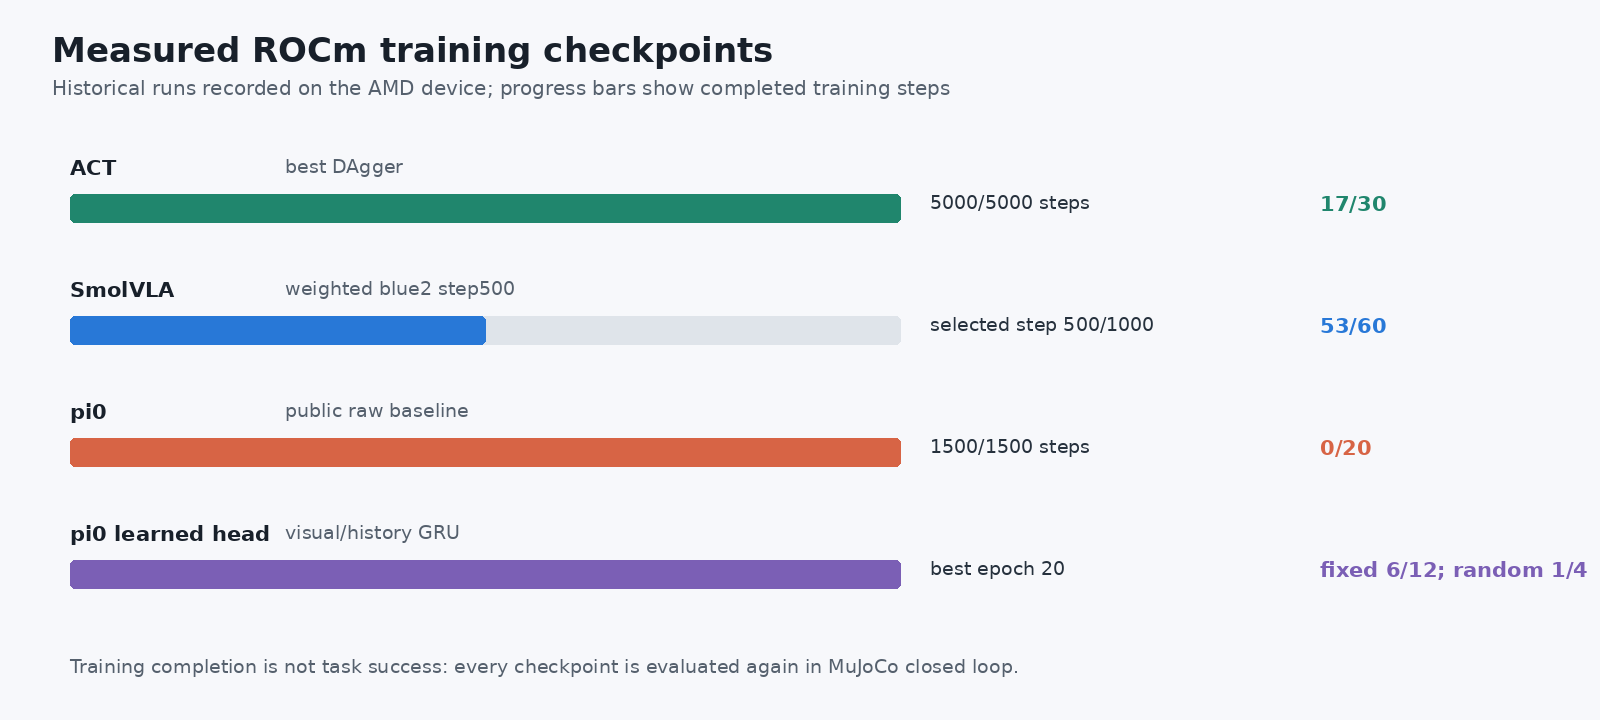

smolvla_red_blue_success.png

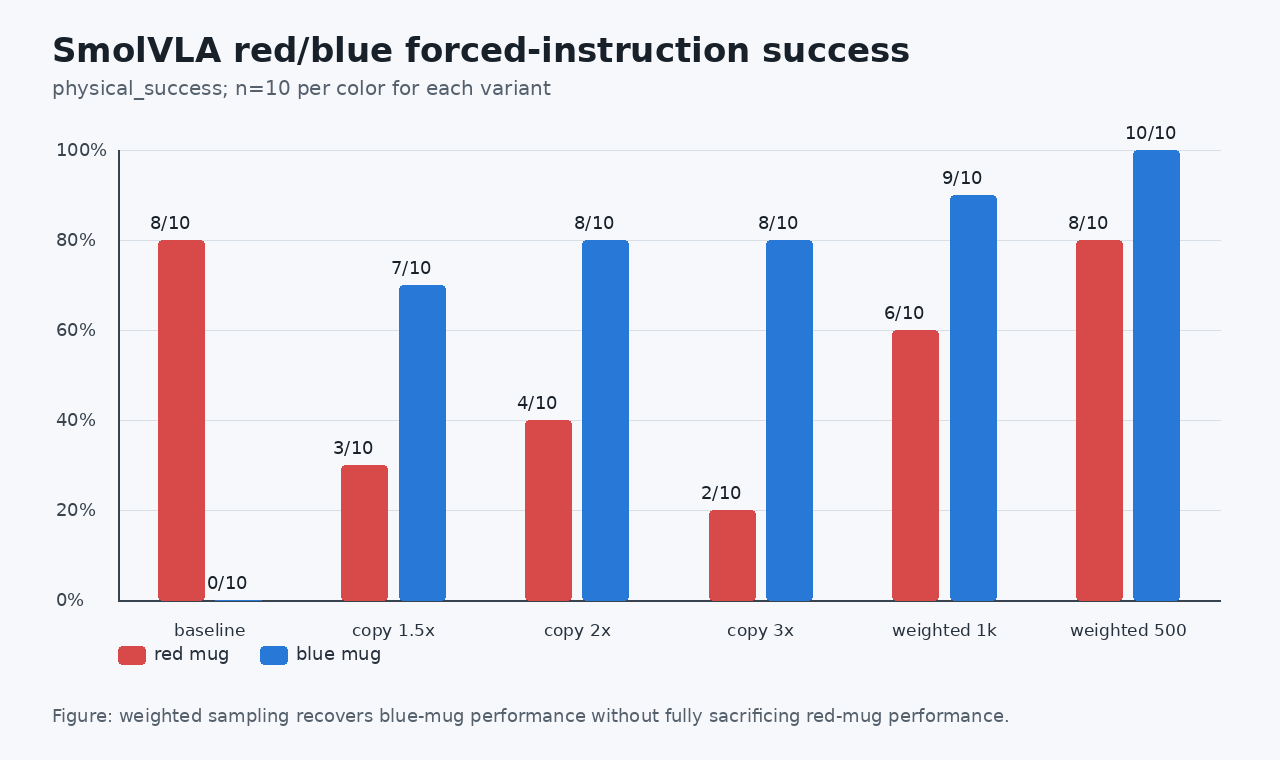

smolvla_blue_success_sequence.jpg

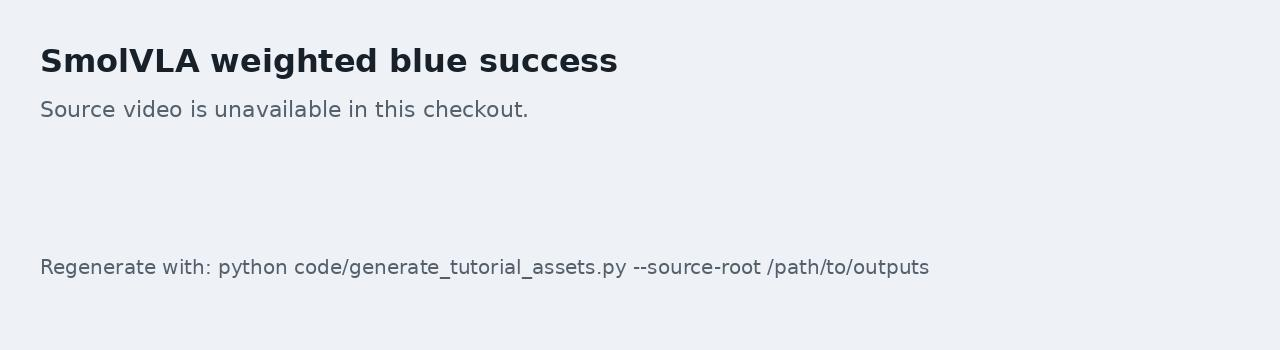

pnp_four_view_strict_success_sequence.jpg

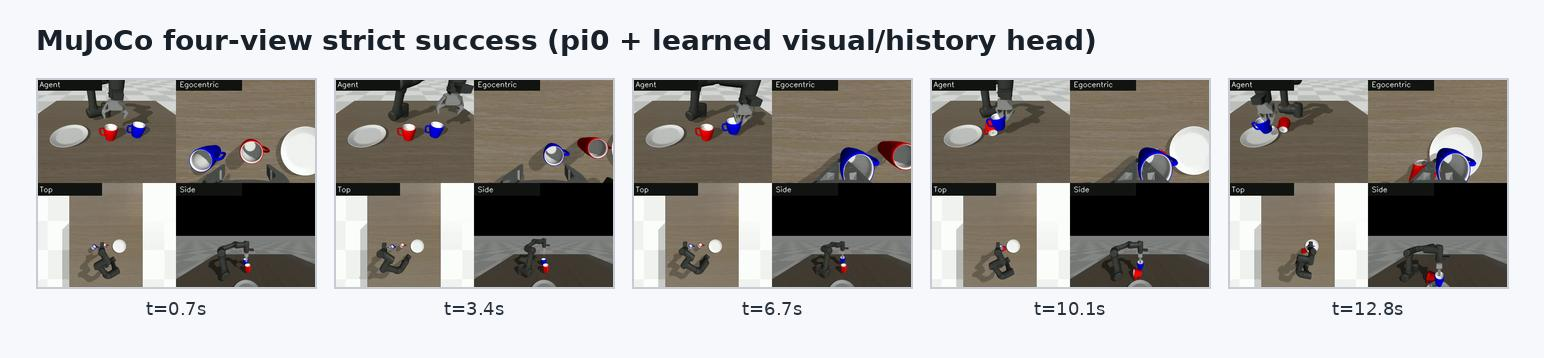

In [4]:
for filename in ["training_progress_overview.png", "smolvla_red_blue_success.png", "smolvla_blue_success_sequence.jpg", "pnp_four_view_strict_success_sequence.jpg"]:
    display(Markdown(filename))
    display(Image(filename=str(TOPIC / "assets" / filename)))


## 继续实训

- [从零采集](07_data_collection_and_audit.ipynb)
- [轻量语言策略完整训练与评估](14_smolvla_end_to_end.ipynb)
- [动作分块策略完整训练与评估](16_act_end_to_end.ipynb)
- [普通／保护训练六本独立工作流](workflows/README.md)
